# HW10 Part 1: Data preparation
**Project F1: Moodle Activity, Denis Artemjev**

Here we make **one table for the whole team**. One row is one student in one year. It says if the student failed the course, and how the student used Moodle before the prediction is made.

The prediction is made at the **cutoff**, one week before the first midterm. At this moment the teacher still has time to help, so we only use data from before the cutoff.

The code that builds the table is in `src/prepare.py`. Ander and I load the table with the same function, so we all use the same data. This notebook answers **Task 1** of HW10.

In [1]:
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")                     # so Python can find the src folder from hw10/
from src.prepare import build_features, COMPONENT_GROUPS

os.makedirs("../results/figures", exist_ok=True)   # folder for poster figures

## Task 1a: The prepared data

In [2]:
# The table that the models use
df = build_features("../data")

print("rows, columns:", df.shape)
print(list(df.columns))
df.head()

rows, columns: (843, 17)
['year', 'actor_id', 'fail', 'is_repeat', 'active_days', 'active_weeks', 'first_day_lag', 'active_weeks_share', 'active_days_last_2_weeks', 'days_forum', 'days_grades', 'days_homework', 'days_lectures', 'days_materials', 'hw_early_count', 'hw_early_submitted_share', 'hw_early_mean']


,year,actor_id,fail,is_repeat,active_days,active_weeks,first_day_lag,active_weeks_share,active_days_last_2_weeks,days_forum,days_grades,days_homework,days_lectures,days_materials,hw_early_count,hw_early_submitted_share,hw_early_mean
0,2019,S027cf9,0,0,18,6,19,0.666667,5,0,1,18,0,4,5,1.0,83.8
1,2019,S032255,0,0,6,5,21,0.555556,2,1,0,6,0,2,5,0.4,4.4
2,2019,S03a8b8,0,0,30,8,0,0.888889,9,1,16,22,0,10,5,1.0,106.4
3,2019,S04cf7f,0,0,21,9,6,1.000000,7,0,5,18,0,3,5,1.0,94.4
4,2019,S05f285,1,0,32,7,7,0.777778,13,2,25,25,0,12,5,1.0,86.2


The table has 843 rows and 17 columns. One row is one student in one year (2019 and 2021 to 2026). The column `fail` is what we want to predict, and 14 columns are features. The next tasks show how we got here from the raw data.

## Task 1b: What we had to fix in the data

To show the problems, we load the raw data in the same way as in HW7.

In [3]:
years = [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]

events_list = []
grades_list = []
for year in years:
    events_list.append(pd.read_parquet("../data/" + str(year) + "/events.parquet"))
    grades_list.append(pd.read_csv("../data/" + str(year) + "/grades.csv"))

events = pd.concat(events_list, ignore_index=True)
grades = pd.concat(grades_list, ignore_index=True)
for table in [events, grades]:
    table["year"] = table["course_run_id"].str[-4:].astype(int)

print("events:", events.shape)
print("grades:", grades.shape)

events: (972372, 10)
grades: (945, 42)


**Problem 1: duplicate events.** Many rows are the same except for `event_id`.

In [4]:
cols = ["course_run_id", "event_time", "actor_id", "affected_actor_id",
        "event_context", "component", "event_name", "origin"]
duplicates = events.duplicated(subset=cols)

print("duplicate rows:", duplicates.sum(), "of", len(events))

# Events per student in one year: some students have a huge number
per_student = events[events["actor_id"] != "T"].groupby(["year", "actor_id"]).size()
print("events per student: median", per_student.median(), ", max", per_student.max())

duplicate rows: 145936 of 972372
events per student: median 641.0 , max 10205


About 15% of the rows (145,936) are duplicates. In 2019 to 2023 the time is saved only to the minute, so different clicks in the same minute look the same. One student has 10,205 events while the median is 641.

**What we did:** we don't count events. We count **active days**: on how many different days the student did something in Moodle. Duplicates and a lot of clicks on one day don't change this number.

**Problem 2: an English and an Estonian score for the same task.** Every task has two columns, for example `homework_01_eng` and `homework_01_est`. In HW7 we found 584 cases where both are filled in.

In [5]:
# All cases where a student has both scores for the same task
both = []
for col in grades.columns:
    if col.endswith("_eng"):
        task = col[:-4]                       # "homework_01_eng" -> "homework_01"
        rows = grades[grades[col].notna() & grades[task + "_est"].notna()]
        for eng, est in zip(rows[col], rows[task + "_est"]):
            both.append({"task": task, "eng": eng, "est": est})
both = pd.DataFrame(both)

print("cases with both scores:", len(both))
print("one of the two scores is 0:", ((both["eng"] == 0) | (both["est"] == 0)).sum())
both.head()

cases with both scores: 584
one of the two scores is 0: 544


,task,eng,est
0,homework_01,0.0,99.0
1,homework_01,0.0,110.0
2,homework_01,0.0,99.0
3,homework_01,0.0,88.0
4,homework_01,0.0,99.0


In 544 of the 584 cases one of the two scores is 0, so the 0 is just an empty cell in the other language.

**What we did:** we keep one column per task with the **higher** score.

**Problem 3: Moodle tools changed over the years.** For example, homework was submitted with different tools in different years.

In [6]:
# Student events in the two homework tools, by year
student_events = events[events["actor_id"] != "T"]
tools = student_events[student_events["component"].isin(["Assignment", "Quiz"])]
pd.crosstab(tools["year"], tools["component"])

component,Assignment,Quiz
year,,
2019,11211,3938
2020,27609,14782
2021,0,64781
2022,0,33690
2023,3137,36699
2024,2542,58528
2025,15680,11699
2026,13983,10692


In 2021 and 2022 there were no Assignment events at all, all homework was a Quiz. In 2019, 2025 and 2026 Assignment was used a lot. If we counted each tool on its own, it would look like students in 2021 "never did homework".

**What we did:** we put the tools into five general groups (materials, homework, lectures, forum, grades) and count the days for each group. Marina uses the same groups.

In [7]:
pd.Series(COMPONENT_GROUPS, name="group").sort_values()

Forum                          forum
User report                   grades
Overview report               grades
Assignment                  homework
Quiz                        homework
File submissions            homework
Online text submissions     homework
BigBlueButton               lectures
BigBlueButtonBN             lectures
File                       materials
URL                        materials
Folder                     materials
Page                       materials
Name: group, dtype: str

**Problem 4: missing values.**

In [8]:
graded = grades[grades["year"] != 2020]
print("students in 2020:", (grades["year"] == 2020).sum(), ", with a grade:",
      grades.loc[grades["year"] == 2020, "course_letter_grade"].notna().sum())
print("empty grade in other years:", graded["course_letter_grade"].isna().sum())
print("grade F in other years:", (graded["course_letter_grade"] == "F").sum())
print("students with no Moodle activity before the cutoff:", (df["active_days"] == 0).sum())

students in 2020: 102 , with a grade: 0
empty grade in other years: 65
grade F in other years: 62
students with no Moodle activity before the cutoff: 5


- **2020 has no grades at all.** Without a grade we don't know who failed, so we removed 2020 from this table. Marina still uses 2020 in her descriptive part.
- **65 students have an empty grade.** The dataset README says that an empty grade means the student did not come to the exam, so we count them as failed, like F.
- **5 students have no Moodle activity before the cutoff.** We keep them with 0 active days, because "never used Moodle" is also information.
- **A missing homework score** means the homework was not submitted, so in the homework mean it counts as 0 points.

## Task 1c: What one row is and what goes into the analysis

**One row** = one student in one year. A student who took the course twice has two rows.

**Columns we kept:** `year` and `actor_id` (to know who the row is about; not used by the models).

**New columns we built:**

| Column | Meaning |
|---|---|
| `fail` | **the target**: 1 = grade F or no grade, 0 = grade A to E |
| `is_repeat` | 1 if the student already took the course in an earlier year |
| `active_days` | on how many days the student used Moodle before the cutoff |
| `active_weeks` | in how many weeks the student used Moodle |
| `active_weeks_share` | the same as a share of all weeks before the cutoff (years have a different number of weeks) |
| `first_day_lag` | how many days after the start the student first used Moodle |
| `active_days_last_2_weeks` | active days in the last 2 weeks before the cutoff |
| `days_materials`, `days_homework`, `days_lectures`, `days_forum`, `days_grades` | on how many days the student used each group of tools |
| `hw_early_count` | how many homeworks had their deadline before the cutoff (3 to 5) |
| `hw_early_submitted_share` | what share of these homeworks the student submitted |
| `hw_early_mean` | mean score of these homeworks (a missing homework is 0 points) |

In HW7 we decided to compare a model with only the activity features and a model with activity **and** early homework, so the homework features are a separate group.

**Columns we left out:**
- midterm and exam scores, the numeric grade and the bonus: they are known only after the cutoff (see Task 1d);
- homework with a deadline after the cutoff;
- teacher events, `event_id`, `origin`: they say nothing about the student;
- course page views (`System`): almost the same as `active_days` (they happen on 91% of the active days), so they add nothing new.

## Task 1d: How we split the data, and how we avoided a leak

**Split by time.** We train on the older years (2019, 2021 to 2024) and test on the newest years (2025 and 2026). A teacher would use the model on a new year, so we test it in the same way. A random split would mix students of the same year into train and test, and the result would look better than it really is.

In [9]:
train = df[df["year"].isin([2019, 2021, 2022, 2023, 2024])]
test = df[df["year"].isin([2025, 2026])]

split = pd.DataFrame({
    "students": [len(train), len(test)],
    "failed": [train["fail"].sum(), test["fail"].sum()],
}, index=["train (2019, 2021-2024)", "test (2025-2026)"])
split["failed, %"] = (split["failed"] / split["students"] * 100).round(1)
split

,students,failed,"failed, %"
"train (2019, 2021-2024)",564,82,14.5
test (2025-2026),279,45,16.1


**Leak.** A leak is information that the teacher would not have at the moment of the prediction. The biggest danger in our data is everything that happens after the cutoff: the midterm and exam scores, the final grade, and Moodle activity in the last week before the midterm, when students study the most (Marina's Fig. 1b). If we used them, the model would look great but would be useless for the teacher.

**How we avoided it:** all features are counted only from events before the cutoff, and we only use homework with a deadline before the cutoff. The table below shows that the last early homework deadline is always before the cutoff.

In [10]:
calendar = pd.concat([pd.read_csv("../data/" + str(y) + "/calendar.csv") for y in years], ignore_index=True)
calendar["year"] = calendar["course_run_id"].str[-4:].astype(int)
calendar["start_time"] = pd.to_datetime(calendar["start_time"], utc=True)
calendar["end_time"] = pd.to_datetime(calendar["end_time"], utc=True)

# Cutoff = first midterm minus 7 days
midterm = calendar[calendar["activity_name"] == "midterm_attempt_1"].set_index("year")["start_time"]
cutoff = midterm - pd.Timedelta(days=7)

# Homework with a deadline before the cutoff
homework = calendar[calendar["activity_type"] == "homework"].copy()
early = homework[homework["end_time"] < homework["year"].map(cutoff)]

check = pd.DataFrame({
    "first midterm": midterm.dt.date,
    "cutoff": cutoff.dt.date,
    "early homeworks": early.groupby("year").size(),
    "last early deadline": early.groupby("year")["end_time"].max().dt.date,
})
check

,first midterm,cutoff,early homeworks,last early deadline
year,,,,
2019,2019-04-15,2019-04-08,5,2019-04-01
2020,2020-04-17,2020-04-10,5,2020-04-08
2021,2021-04-16,2021-04-09,5,2021-04-05
2022,2022-04-08,2022-04-01,3,2022-03-25
2023,2023-04-14,2023-04-07,4,2023-03-28
2024,2024-04-19,2024-04-12,5,2024-04-08
2025,2025-04-11,2025-04-04,4,2025-04-01
2026,2026-04-17,2026-04-10,5,2026-04-09


There is one small risk left. A homework deadline can be only a day before the cutoff (for example 2026), and the teacher may not have graded it yet. Then the teacher would still see that the homework was submitted (`hw_early_submitted_share`), but maybe not the score. That's one more reason why we compare a model with and a model without the homework scores.

## Are the features useful?

Before giving the table to the models, we check in a simple way if the features have anything to do with failing. We put students into groups by their active days and by their early homework score, and look at what share of each group failed.

In [11]:
# Groups by active days and by early homework score
days_group = pd.cut(df["active_days"], [-1, 5, 10, 15, 20, 30, 100],
                    labels=["0-5", "6-10", "11-15", "16-20", "21-30", "31+"])
hw_group = pd.cut(df["hw_early_mean"], [-1, 20, 40, 60, 80, 200],
                  labels=["0-20", "21-40", "41-60", "61-80", "81+"])

# Share of failed students (%) and number of students in each group
by_days = df.groupby(days_group, observed=True)["fail"].agg(["mean", "size"])
by_hw = df.groupby(hw_group, observed=True)["fail"].agg(["mean", "size"])
by_days["mean"] = by_days["mean"] * 100
by_hw["mean"] = by_hw["mean"] * 100
all_students = df["fail"].mean() * 100

by_days.round(1)

,mean,size
active_days,,
0-5,90.6,32
6-10,34.5,55
11-15,24.7,146
16-20,12.4,153
21-30,6.2,273
31+,3.8,184


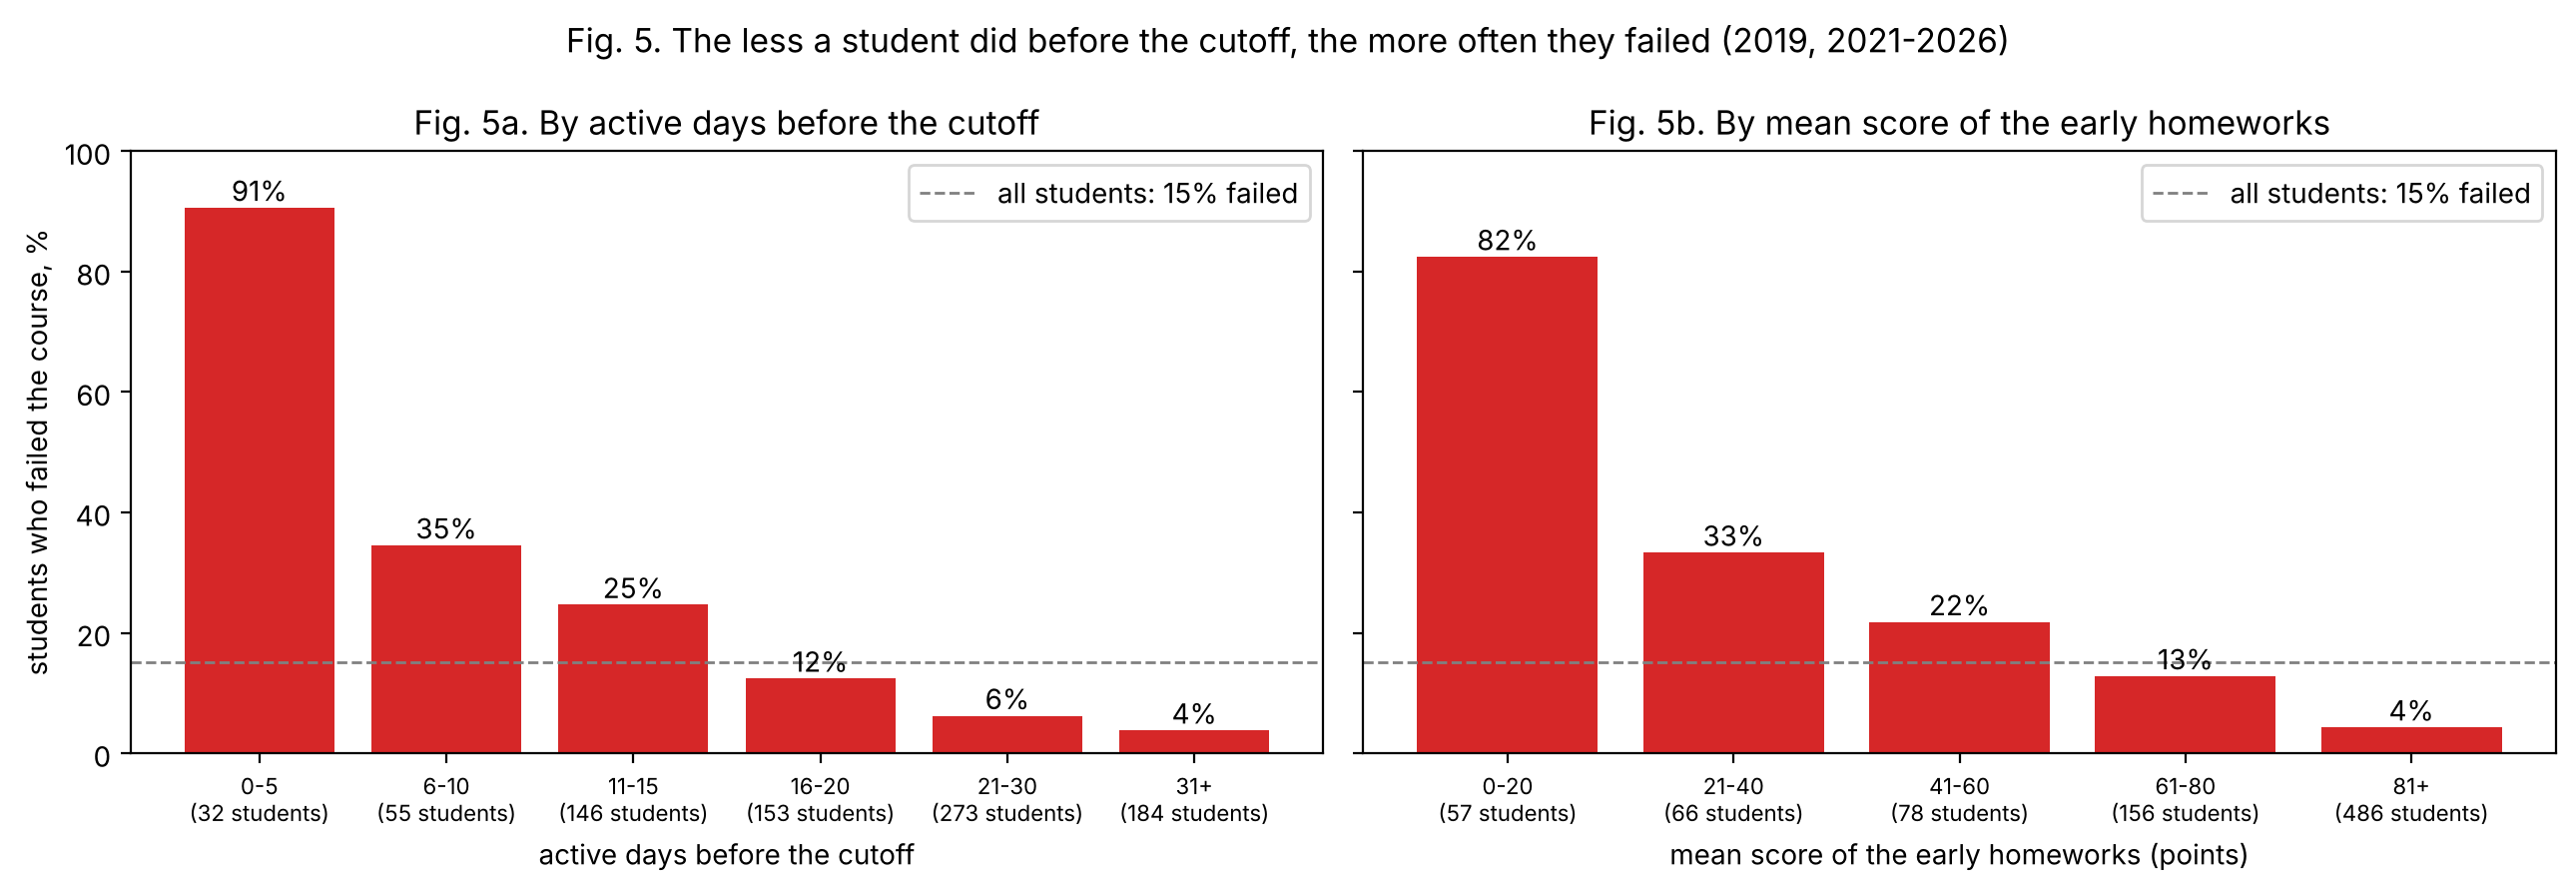

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
panels = [(axes[0], by_days, "Fig. 5a. By active days before the cutoff", "active days before the cutoff"),
          (axes[1], by_hw, "Fig. 5b. By mean score of the early homeworks", "mean score of the early homeworks (points)")]

for ax, table, title, x_label in panels:
    # x labels with the number of students in the group
    labels = [f"{group}\n({n} students)" for group, n in zip(table.index, table["size"])]
    bars = ax.bar(labels, table["mean"], color="tab:red")
    ax.bar_label(bars, fmt="%.0f%%")                         # value on top of each bar
    ax.axhline(all_students, color="gray", linestyle="--", linewidth=1,
               label=f"all students: {all_students:.0f}% failed")
    ax.legend(loc="upper right")
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.tick_params(axis="x", labelsize=8)

axes[0].set_ylabel("students who failed the course, %")
axes[0].set_ylim(0, 100)
fig.suptitle("Fig. 5. The less a student did before the cutoff, the more often they failed (2019, 2021-2026)")
plt.tight_layout()
plt.savefig("../results/figures/prep_fig5_fail_share.pdf", bbox_inches="tight")
plt.show()

Of the students who used Moodle on 5 days or less before the cutoff, 91% failed. Of the students who used it on more than 30 days, only 4% failed. Early homework shows the same: a mean score of 0 to 20 points means 82% failed, 81 points or more means 4%.

So the features are clearly connected to failing, and the models have something to learn from. But most students are in the middle groups, and there the result is mixed: of the students with 11 to 15 active days, 1 of 4 failed and 3 of 4 passed. So the models will still make mistakes.

## Save the table
We save the table into `data/processed/`. The folder `data` is in `.gitignore`, so the data is never uploaded.

In [13]:
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/features.csv", index=False)
print("saved")

saved


## Summary

1. **One table for the team:** 843 students (2019, 2021 to 2026), the target `fail` and 14 features.
2. **Fixed problems:** duplicates (we count active days), two scores per task (we take the higher one), tools that changed over the years (five groups), no grades in 2020 (removed), empty grades (counted as failed).
3. **No leak:** only data from before the cutoff, one week before the first midterm.
4. **Split by time:** train on 2019 and 2021 to 2024, test on 2025 and 2026.
5. **The features are useful:** students who did less in Moodle and in the early homework failed much more often.